In [9]:
from article_utils.util import read_jsonl
import glob
import seaborn as sns
import pandas as pd


df = read_jsonl(*[f for f in glob.glob('subset-*/*.jsonl') if not f.endswith('admin.jsonl')], add_filename=True)

names_df = df[['filename']].drop_duplicates()
names_df['curator'] = names_df.filename.str.extract(r'.*/([^.]+)\.jsonl$')

df = df.merge(names_df)
df['example_id'] = df['display_id'] = df.meta.str['example_id']
df['predicted_label_name'] = df.label.str[0]

print(f'there are {df.example_id.nunique()} unique examples')
print(f'there are {df.curator.nunique()} unique curators')
df

there are 300 unique examples
there are 9 unique curators


,id,text,meta,label,Comments,filename,curator,example_id,display_id,predicted_label_name
0,9168,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '1b081473-9a3f-466d-80c7-773dbf...,[NEI],[Should be more evidence(s) such as symptoms o...,subset-0/Mariam_Khanfar.jsonl,Mariam_Khanfar,1b081473-9a3f-466d-80c7-773dbf02e801,1b081473-9a3f-466d-80c7-773dbf02e801,NEI
1,9169,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'e7029c89-5dcc-4921-b021-ece98c...,[SUPPORTS],[],subset-0/Mariam_Khanfar.jsonl,Mariam_Khanfar,e7029c89-5dcc-4921-b021-ece98c927ccb,e7029c89-5dcc-4921-b021-ece98c927ccb,SUPPORTS
2,9170,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'a1204510-81ba-493d-a4db-aa1963...,[REFUTES],[],subset-0/Mariam_Khanfar.jsonl,Mariam_Khanfar,a1204510-81ba-493d-a4db-aa1963f81f98,a1204510-81ba-493d-a4db-aa1963f81f98,REFUTES
3,9171,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '2f2e2061-9cfa-49bc-8371-ff19b7...,[REFUTES],[],subset-0/Mariam_Khanfar.jsonl,Mariam_Khanfar,2f2e2061-9cfa-49bc-8371-ff19b7ba041c,2f2e2061-9cfa-49bc-8371-ff19b7ba041c,REFUTES
4,9172,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '72d8ce19-b86f-48f8-9a56-0f4ed9...,[NEI],[],subset-0/Mariam_Khanfar.jsonl,Mariam_Khanfar,72d8ce19-b86f-48f8-9a56-0f4ed922affd,72d8ce19-b86f-48f8-9a56-0f4ed922affd,NEI
...,...,...,...,...,...,...,...,...,...,...
895,9661,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '28fc1070-3c9e-4be8-89ba-93ccf7...,[SUPPORTS],[],subset-4/malachig.jsonl,malachig,28fc1070-3c9e-4be8-89ba-93ccf7f8fcae,28fc1070-3c9e-4be8-89ba-93ccf7f8fcae,SUPPORTS
896,9662,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'b205e9ca-d161-4a56-a038-2cafdf...,[NEI],[The evidence doesn't seem to say anything abo...,subset-4/malachig.jsonl,malachig,b205e9ca-d161-4a56-a038-2cafdf11d704,b205e9ca-d161-4a56-a038-2cafdf11d704,NEI
897,9663,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '2489d6c7-fabc-4a52-b731-295327...,[NEI],[The claim is predisposing but the evidence do...,subset-4/malachig.jsonl,malachig,2489d6c7-fabc-4a52-b731-295327b12c53,2489d6c7-fabc-4a52-b731-295327b12c53,NEI
898,9664,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'a9f2dfce-6e69-453b-9f45-565548...,[SUPPORTS],[While the evidence mentions a plan to study s...,subset-4/malachig.jsonl,malachig,a9f2dfce-6e69-453b-9f45-565548d615ed,a9f2dfce-6e69-453b-9f45-565548d615ed,SUPPORTS


## Inter-Annotator Agreement Metrics

For all IA caluclations we will exlude the curator who dropped out, malachig

average score: 0.6241922676196029
average count: 25.0
weighted avg: 0.7501656031386252


/var/tmp/ipykernel_407305/1370782746.py:30: UserWarning: The `weights` parameter has no effect with kind='box'.
  fig = sns.catplot(scores_df[scores_df.curator1 != scores_df.curator2], y='curator1', x='score', kind='box', weights='shared_examples_count' )
/projects/creisle_prj/git/thesis_work/.venv/lib/python3.11/site-packages/seaborn/matrix.py:1124: UserWarning: ``square=True`` ignored in clustermap
  warnings.warn(msg)


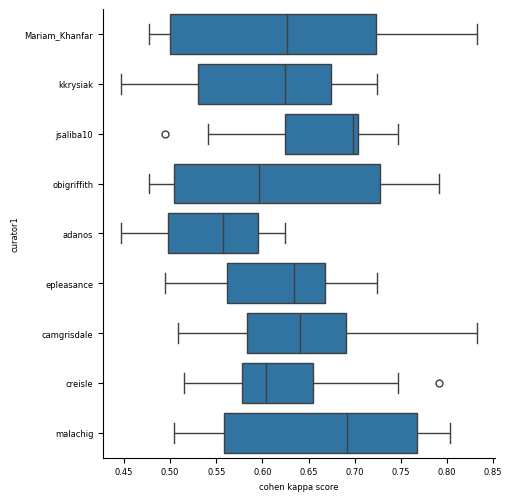

<Figure size 1000x1600 with 0 Axes>

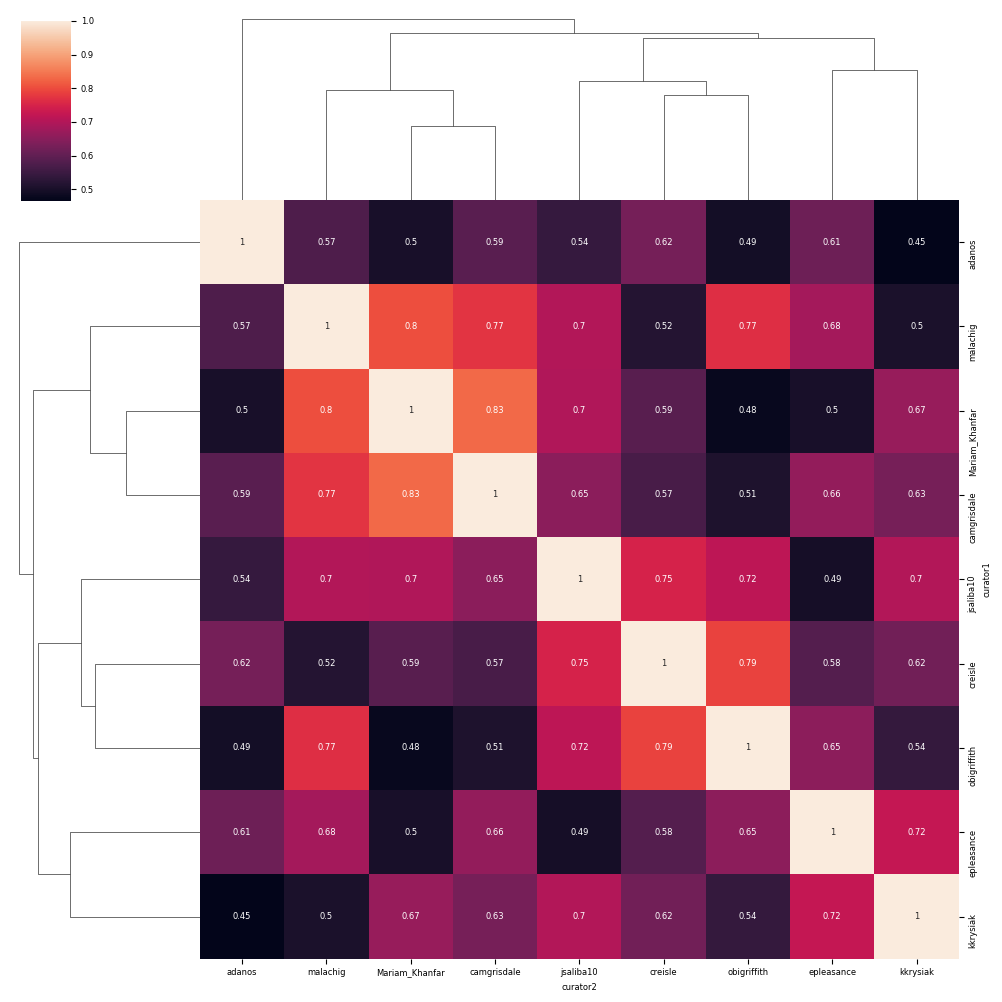

In [10]:
from sklearn.metrics import cohen_kappa_score
import itertools
import numpy as np
from figutils import plot_heatmap

curators = df.curator.unique().tolist()
scores = []
np.seterr(all='raise')
MIN_SHARED_EXAMPLES = 3


for (curator1, curator2) in itertools.product(curators, repeat=2):
    cur1_df = df[df.curator == curator1].rename(columns={'predicted_label_name': 'curator1'})[['curator1', 'display_id']]
    cur2_df = df[df.curator == curator2].rename(columns={'predicted_label_name': 'curator2'})[['curator2', 'display_id']]

    cur_df = cur1_df.merge(cur2_df)
    if cur_df.shape[0] < MIN_SHARED_EXAMPLES:

        print('too few examples', cur_df.shape[0], 'to calculate agreement between', curator1, 'and', curator2)
        continue
    score = cohen_kappa_score(cur_df['curator1'].tolist(), cur_df['curator2'].tolist())
    scores.append({'curator1': curator1, 'curator2': curator2, 'score': score, 'shared_examples_count': cur_df.shape[0]})

scores_df = pd.DataFrame.from_records(scores)
print('average score:', scores_df[scores_df.curator1 != scores_df.curator2].score.mean())
print('average count:', scores_df[scores_df.curator1 != scores_df.curator2].shared_examples_count.mean())
scores_df['w_score'] = scores_df.shared_examples_count * scores_df.score
weight_avg = scores_df.w_score.sum() / scores_df.shared_examples_count.sum()
print('weighted avg:', weight_avg)
fig = sns.catplot(scores_df[scores_df.curator1 != scores_df.curator2], y='curator1', x='score', kind='box', weights='shared_examples_count' )
fig.set(xlabel='cohen kappa score')
plot_heatmap(scores_df, rows_col='curator1', cols_col='curator2', data_col='score', col_cluster=True, row_cluster=True)

In [11]:
# calculate Fleiss Kappa score: https://en.wikipedia.org/wiki/Fleiss%27_kappa

# Let N be the total number of elements, let n be the number of ratings per element, and let k be the number of categories into which assignments are made. The elements are indexed by i = 1, ..., N and the categories are indexed by j = 1, ..., k. Let nij represent the number of raters who assigned the i-th element to the j-th category.
# First calculate pj, the proportion of all assignments which were to the j-th category:
from irrCAC.raw import CAC

N = df.display_id.nunique()
n = 3
k = 3

fk = CAC(pd.pivot_table(df, values='predicted_label_name', aggfunc='first', index='display_id', columns='curator')).fleiss()
fk

{'est': {'coefficient_value': 0.64284,
  'coefficient_name': "Fleiss' kappa",
  'confidence_interval': (0.58591, 0.69977),
  'p_value': 0.0,
  'z': 22.22203,
  'se': 0.02893,
  'pa': 0.77444,
  'pe': 0.36848},
 'weights': array([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]]),
 'categories': ['NEI', 'REFUTES', 'SUPPORTS']}